# Tiled inference

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Scaling inference across tiles and comparing results visually
</div>
<!-- markdownlint-enable MD033 -->

---

Everything so far has processed one 128-by-128 patch. This page scales the same workflow to a larger region, checks the seams between tiles, and compares the output against real {term}`aerial imagery <Aerial Imagery>`, with an important caveat about what that comparison can and cannot prove.

---

## 1. Motivation

Real projects rarely need just one small patch enhanced. Knowing how tiling works here, and knowing how to sanity-check output against real high-resolution imagery without over-trusting that check, is what makes this workflow usable beyond a single demonstration patch.

---

## 2. Core idea

For any region larger than {term}`LDSR-S2`'s native 128-by-128 input size, `geoai.super_resolution()` automatically cuts the input into overlapping tiles, runs the encode-denoise-decode pipeline on each independently, and stitches the results back together, blending linearly across the overlaps. This is the same {term}`tiled inference <Tiled Inference>` idea you have seen in detection, segmentation and change detection. What is new here is that each tile is *generated* independently, so neighbouring tiles may draw the same 10 m pixel in slightly different ways, and the blending must hide that.

---

## 3. Workflow

### A. Set up

Start by loading the same Granada scene as on the previous pages. If the file was already downloaded there, it is reused rather than downloaded again.

In [1]:
import contextlib
import io
import re
import time
import warnings

import geoai
import numpy as np
import rasterio as rio
import requests
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
from PIL import Image
from rasterio.windows import Window

warnings.filterwarnings("ignore")

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L09/data/S2A_L2A_20260802_N0512_R094_subset_Granada.tif"
s2_path = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

ROW, COL, SIZE = 700, 1300, 256  # four times the area of the single patch
PATCH, OVERLAP = 128, 16         # tile size and overlap, in 10 m input pixels
STEPS = 10                       # sampling steps, as chosen on page 5

### B. Plan the tiles

A 256 × 256 region is four times the area of one patch, so you might expect four tiles. With overlap, it is more:

In [2]:
def tile_starts(length, patch, overlap):
    """Tile start positions along one axis, following geoai's tiling rule."""
    stride = patch - overlap
    starts = list(range(0, length - patch + 1, stride))
    if starts[-1] + patch < length:  # add a last tile flush with the edge if needed
        starts.append(length - patch)
    return starts

for overlap in [OVERLAP, 0]:
    starts = tile_starts(SIZE, PATCH, overlap)
    print(f"overlap={overlap:>2}: tile starts {starts} -> {len(starts) ** 2} tiles")

overlap=16: tile starts [0, 112, 128] -> 9 tiles
overlap= 0: tile starts [0, 128] -> 4 tiles


With `overlap=16`, consecutive tiles start 112 pixels apart (128 − 16). Two tiles cover only 0–240, so a third tile is needed to reach 256; it is placed flush with the edge, starting at 128, and overlaps its neighbour almost completely. Three tiles per axis means nine model runs instead of four. The figure shows the layout, and how much weight each output pixel of a tile receives when tiles are blended:

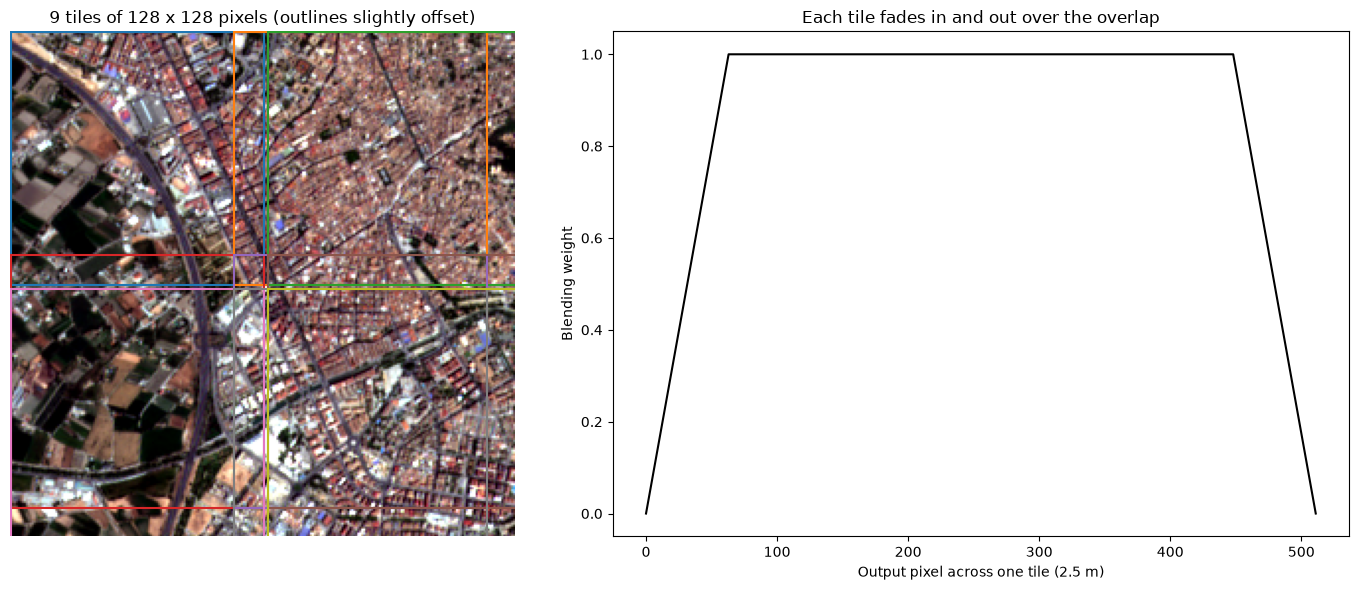

In [3]:
with rio.open(s2_path) as src:
    lr = src.read(window=Window(COL, ROW, SIZE, SIZE)).astype(np.float32) / 10_000
p2 = np.percentile(lr[:3], 2, axis=(1, 2), keepdims=True)
p98 = np.percentile(lr[:3], 98, axis=(1, 2), keepdims=True)

def show(img):
    """Return an RGB image (height, width, 3) stretched with the 10 m input's percentiles."""
    return np.clip((img[:3] - p2) / (p98 - p2), 0, 1).transpose(1, 2, 0)

starts = tile_starts(SIZE, PATCH, OVERLAP)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].imshow(show(lr))
colors = plt.cm.tab10.colors
for k, (r, c) in enumerate([(r, c) for r in starts for c in starts]):
    axes[0].add_patch(Rectangle((c + k % 3, r + k // 3), PATCH, PATCH, fill=False,
                                edgecolor=colors[k], linewidth=1.5))
axes[0].set_title(f"{len(starts) ** 2} tiles of {PATCH} x {PATCH} pixels (outlines slightly offset)")
axes[0].set_axis_off()

ramp = OVERLAP * 4  # the overlap in 2.5 m output pixels
weights = np.ones(PATCH * 4)
weights[:ramp] = np.linspace(0, 1, ramp)
weights[-ramp:] = np.linspace(1, 0, ramp)
axes[1].plot(weights, color="black")
axes[1].set_xlabel("Output pixel across one tile (2.5 m)")
axes[1].set_ylabel("Blending weight")
axes[1].set_title("Each tile fades in and out over the overlap")
plt.tight_layout()
plt.show()

Where two tiles overlap, the output is a weighted average of both: one tile fades out while its neighbour fades in. Without overlap, there is nothing to blend, and each tile's output meets the next one at a hard edge.

### C. Run tiled super-resolution

In [4]:
sr_large = str(OUT_DIR / "sr_large.tif")

start = time.perf_counter()
with contextlib.redirect_stdout(io.StringIO()):  # hide the model's loading messages
    sr_large_img, _ = geoai.super_resolution(
        input_lr_path=s2_path,
        output_sr_path=sr_large,
        rgb_nir_bands=[1, 2, 3, 4],
        window=(ROW, COL, SIZE, SIZE),
        patch_size=PATCH,
        overlap=OVERLAP,
        sampling_steps=STEPS,
    )

print(f"Input shape: (4, {SIZE}, {SIZE}) at 10 m")
print(f"Output shape: {sr_large_img.shape} at 2.5 m")
print(f"Runtime: {time.perf_counter() - start:.0f} s")

Input shape: (4, 256, 256) at 10 m
Output shape: (4, 1024, 1024) at 2.5 m
Runtime: 188 s


`patch_size=128` matches the model's native input size from page 4; `overlap=16` controls how many pixels adjacent tiles share. Larger overlap values give smoother transitions between tiles, at the cost of more tiles and more computation time, the familiar quality-versus-cost trade-off from earlier pages.

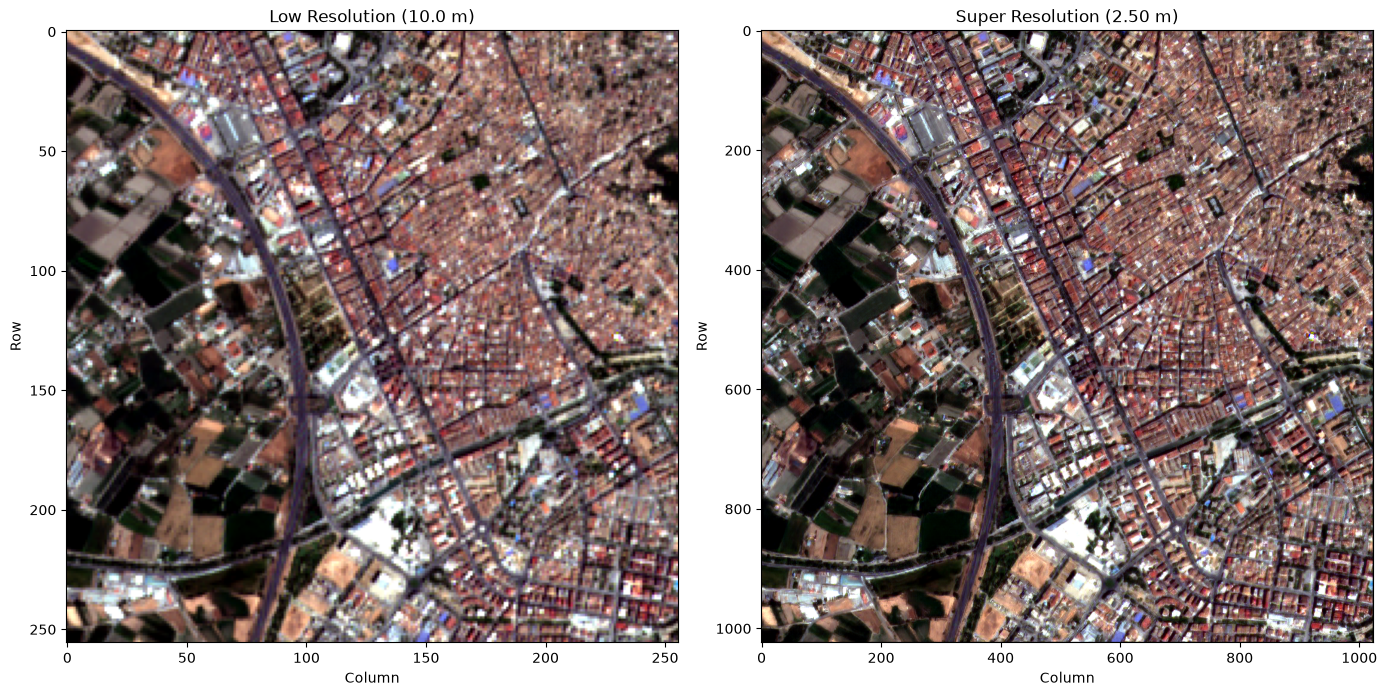

In [5]:
geoai.plot_sr_comparison(s2_path, sr_large, bands=[1, 2, 3])
plt.show()

This is the quick comparison function from page 5, now applied to the full stitched output. At this scale, no tile boundaries are visible.

### D. Check the seams

To see what the overlap does, run the same region with `overlap=0`, which needs only four tiles, and compare how strongly neighbouring columns differ. A seam shows up as a jump between two adjacent columns that is larger than usual.

In [6]:
sr_no_overlap = str(OUT_DIR / "sr_large_no_overlap.tif")
with contextlib.redirect_stdout(io.StringIO()):
    sr_no_overlap_img, _ = geoai.super_resolution(
        input_lr_path=s2_path,
        output_sr_path=sr_no_overlap,
        window=(ROW, COL, SIZE, SIZE),
        patch_size=PATCH,
        overlap=0,
        sampling_steps=STEPS,
    )

def column_jumps(img):
    """Mean absolute brightness change between each column and the next one."""
    brightness = img[:3].mean(axis=0)
    return np.abs(np.diff(brightness, axis=1)).mean(axis=0)

boundary = PATCH * 4 - 1  # the last column of the first tile without overlap (2.5 m pixels)
for name, img in [("overlap=0 ", sr_no_overlap_img), ("overlap=16", sr_large_img)]:
    jumps = column_jumps(img)
    print(f"{name}: jump at the tile boundary {jumps[boundary]:.4f}, "
          f"median jump {np.median(jumps):.4f}  (ratio {jumps[boundary] / np.median(jumps):.1f})")

overlap=0 : jump at the tile boundary 0.0328, median jump 0.0208  (ratio 1.6)
overlap=16: jump at the tile boundary 0.0191, median jump 0.0175  (ratio 1.1)


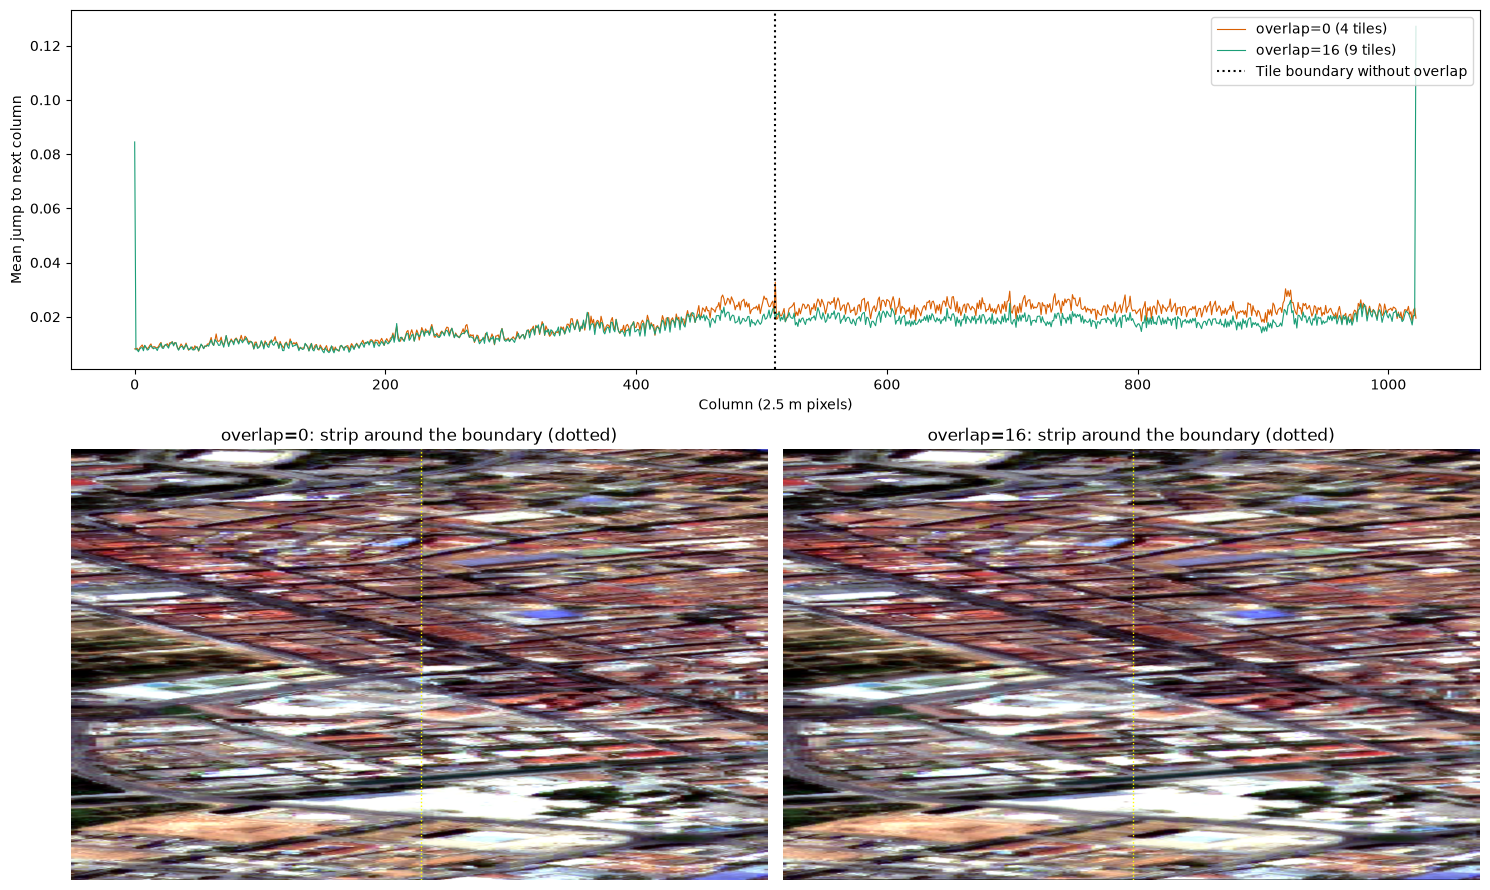

In [7]:
fig = plt.figure(figsize=(15, 9))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])
ax = fig.add_subplot(grid[0, :])
ax.plot(column_jumps(sr_no_overlap_img), label="overlap=0 (4 tiles)", color="#d95f02", linewidth=0.8)
ax.plot(column_jumps(sr_large_img), label="overlap=16 (9 tiles)", color="#1b9e77", linewidth=0.8)
ax.axvline(boundary, color="black", linestyle=":", label="Tile boundary without overlap")
ax.set_xlabel("Column (2.5 m pixels)")
ax.set_ylabel("Mean jump to next column")
ax.legend(loc="upper right")

z = (slice(0, 1024), slice(boundary - 96, boundary + 96))  # a vertical strip around the boundary
for k, (name, img) in enumerate([("overlap=0", sr_no_overlap_img), ("overlap=16", sr_large_img)]):
    sub = fig.add_subplot(grid[1, k])
    sub.imshow(show(img[:, z[0], z[1]]), aspect="auto")
    sub.axvline(96, color="yellow", linestyle=":", linewidth=1)
    sub.set_title(f"{name}: strip around the boundary (dotted)")
    sub.set_axis_off()
plt.tight_layout()
plt.show()

The seam check makes the purpose of `overlap` measurable. The jump between the two columns where the tiles meet is compared with the typical (median) jump between neighbouring columns: a ratio well above 1 means a seam. Without overlap, the jump at the tile boundary is clearly larger than usual and stands out as a spike in the profile; with overlap, it is barely above the normal variation. In the image strips, the seam is subtle even without overlap: look for roofs and small streets that do not continue cleanly across the dotted line. Because LDSR-S2 keeps each tile's 10 m averages fixed (page 5), seams cannot change the overall brightness, only the generated detail: a roof edge drawn slightly differently on either side of the line.

The profile shows two more things worth a closer look: with overlap, the curve is lower over most of the image, and it has sharp spikes at the very first and last columns.

### E. Side effects of blending

In [8]:
def sharpness(img):
    """Mean edge strength of the RGB brightness: higher means sharper."""
    gy, gx = np.gradient(img[:3].mean(axis=0))
    return np.hypot(gx, gy).mean()

# 1. The outermost pixels
for name, img in [("overlap=0 ", sr_no_overlap_img), ("overlap=16", sr_large_img)]:
    frame = np.concatenate([img[:, 0, :], img[:, -1, :], img[:, :, 0], img[:, :, -1]], axis=1)
    print(f"{name}: share of zero values in the outermost rows and columns: {np.mean(frame == 0):.0%}")

# 2. Sharpness where only one tile contributes, and where four tiles are blended
regions = {"one tile ": (slice(64, 448), slice(64, 448)),
           "four tiles": (slice(576, 896), slice(576, 896))}
for region, (rs, cs) in regions.items():
    print(f"Area covered by {region}: sharpness overlap=0 {sharpness(sr_no_overlap_img[:, rs, cs]):.4f}, "
          f"overlap=16 {sharpness(sr_large_img[:, rs, cs]):.4f}")

# 3. Agreement with the 10 m input
for name, img in [("overlap=0 ", sr_no_overlap_img), ("overlap=16", sr_large_img)]:
    deviation = np.abs(img.reshape(4, SIZE, 4, SIZE, 4).mean(axis=(2, 4)) - lr)
    print(f"{name}: deviation from the 10 m input, mean {deviation.mean():.4f}, "
          f"largest inside the image {deviation[:, 1:-1, 1:-1].max():.4f}")

overlap=0 : share of zero values in the outermost rows and columns: 0%
overlap=16: share of zero values in the outermost rows and columns: 100%
Area covered by one tile : sharpness overlap=0 0.0171, overlap=16 0.0171
Area covered by four tiles: sharpness overlap=0 0.0228, overlap=16 0.0192
overlap=0 : deviation from the 10 m input, mean 0.0000, largest inside the image 0.0000
overlap=16: deviation from the 10 m input, mean 0.0007, largest inside the image 0.0125


Blending has three side effects, all visible in these numbers:

1. **A black frame.** With overlap, every value in the outermost row and column of the output is zero. `geoai` (version 0.43) fades each tile in from a weight of zero, also at the outer edge of the whole image, where no neighbouring tile takes over. The result is a one-pixel black frame at 2.5 m, which explains the spikes at both ends of the profile. Crop it, or set it to nodata, before using the output; this is the kind of detail you only find by checking.
2. **Slightly smoother detail where tiles overlap.** Two tiles generate *different* plausible details for the same place (page 6), and averaging them blurs those details a little. Where four tiles are blended, the output is noticeably less sharp than without overlap; where only one tile contributes, sharpness is almost the same. This is why the green curve in the profile is lower over most of the image.
3. **Approximate, not exact, agreement with the input.** A single patch matches the 10 m input exactly (page 5). After blending, the 10 m averages deviate slightly, by less than a thousandth of reflectance on average and about a hundredth at most, because the correction step works on each tile before blending. Without overlap, the agreement stays exact.

None of these effects is large, but together they show that tiling is not neutral: it is a design choice with costs, like every other parameter in this workflow.

### F. Compare against aerial imagery

Is the generated detail real? The only way to find out is to compare it with imagery that *observed* that detail. Spain's national orthophoto programme, **{abbr}`PNOA (Plan Nacional de Ortofotografía Aérea, Spain's national aerial orthophoto programme)`**, provides free aerial imagery at 25 cm through a public web map service (WMS) of the Instituto Geográfico Nacional (IGN), under a CC BY 4.0 licence (attribution: PNOA © Instituto Geográfico Nacional de España). The code requests an image covering exactly the footprint of the super-resolved output, and asks the service when the aerial photos were taken:

In [9]:
PNOA_WMS = "https://www.ign.es/wms-inspire/pnoa-ma"

with rio.open(sr_large) as src:
    left, bottom, right, top = src.bounds
    crs = src.crs.to_string()

common = {"SERVICE": "WMS", "VERSION": "1.3.0", "STYLES": "", "CRS": crs,
          "BBOX": f"{left},{bottom},{right},{top}"}

response = requests.get(PNOA_WMS, timeout=120, params={
    **common, "REQUEST": "GetMap", "LAYERS": "OI.OrthoimageCoverage",
    "WIDTH": 2048, "HEIGHT": 2048, "FORMAT": "image/jpeg"})
pnoa = np.array(Image.open(io.BytesIO(response.content)))

info = requests.get(PNOA_WMS, timeout=120, params={
    **common, "REQUEST": "GetFeatureInfo", "LAYERS": "OI.MosaicElement",
    "QUERY_LAYERS": "OI.MosaicElement", "WIDTH": 256, "HEIGHT": 256, "I": 128, "J": 128,
    "INFO_FORMAT": "text/html"})
pnoa_date = re.search(r"\d{4}-\d{2}", info.text).group()

print(f"PNOA image: {pnoa.shape}, pixel size {(right - left) / pnoa.shape[1]:.2f} m, flown {pnoa_date}")
print("Sentinel-2 image: acquired 2026-08")

PNOA image: (2048, 2048, 3), pixel size 1.25 m, flown 2022-09
Sentinel-2 image: acquired 2026-08


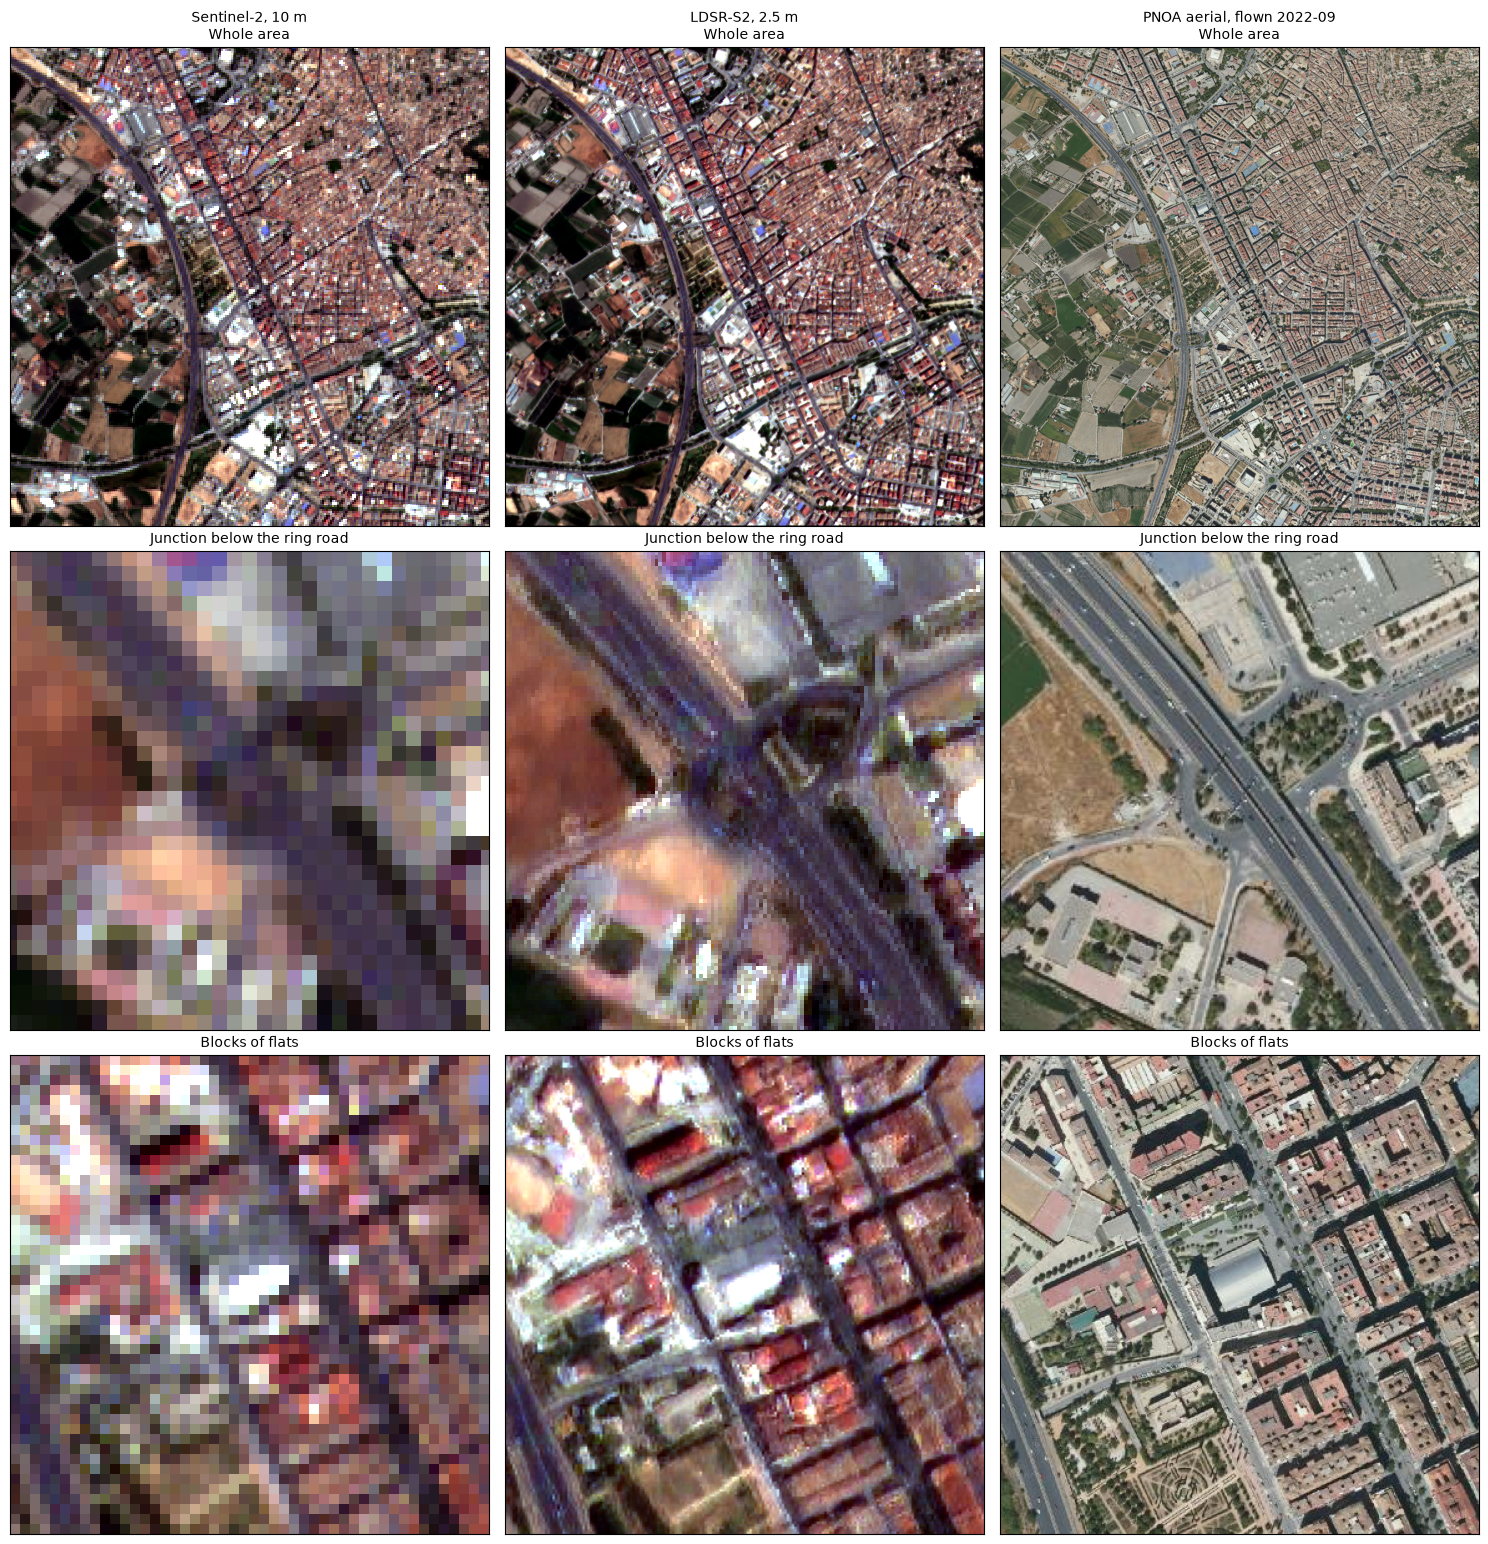

In [10]:
extent = (left, right, bottom, top)
views = {
    "Whole area": (left, right, bottom, top),
    "Junction below the ring road": (445325, 445645, 4114450, 4114770),
    "Blocks of flats": (445700, 446180, 4114090, 4114570),
}
fig, axes = plt.subplots(len(views), 3, figsize=(15, 15.5))
for i, (view, (x0, x1, y0, y1)) in enumerate(views.items()):
    for j, (title, img) in enumerate([("Sentinel-2, 10 m", show(lr)),
                                      ("LDSR-S2, 2.5 m", show(sr_large_img)),
                                      (f"PNOA aerial, flown {pnoa_date}", pnoa)]):
        ax = axes[i, j]
        ax.imshow(img, extent=extent, interpolation="nearest" if j == 0 else "antialiased")
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_title(f"{title}\n{view}" if i == 0 else view, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

`extent=(left, right, bottom, top)` places each image at its map coordinates, so all three columns can be zoomed to exactly the same area with `set_xlim` and `set_ylim`, even though their pixel sizes differ (10 m, 2.5 m and 1.25 m).

Compare the rows column by column:

- **Whole area:** the layout matches well: ring road, street grid, fields and large buildings are all in the right place. That is expected, because these structures are larger than a 10 m pixel and therefore visible in the input.
- **Junction below the ring road:** the aerial image shows a real roundabout below the ring road, so the roundabout the model drew on page 5 is not invented. But its exact shape, the lane markings and the small objects around it are the model's interpretation, not a copy of the aerial view.
- **Blocks of flats:** this is where generated and observed detail part ways. The wide streets are in the right place, because they are visible at 10 m. Within the blocks, the aerial image shows inner courtyards, individual roof shapes, shadows and rows of street trees; the super-resolved image shows a convincing *texture* of red roofs and dark gaps, but courtyards and roofs do not match one-to-one, and the street trees are missing. The large hall with an arched roof in the centre becomes a featureless bright patch. This is exactly where page 6 found the highest uncertainty.

### G. An interactive comparison

For your own exploration, `geoai` can also show the output on an interactive {term}`split-panel map <Split-Panel Map>` against a global {term}`basemap <Basemap>`:

In [11]:
geoai.create_split_map(
    left_layer=sr_large, right_layer="Esri.WorldImagery", left_args={"vmax": 0.3}
)

Dragging the slider reveals how the super-resolved output's fine-scale detail matches what a high-resolution basemap shows in the same location. The interactive map only appears when you run the notebook yourself; it is not shown on this website.

### H. This comparison is qualitative only

```{admonition} Reference imagery is not ground truth for this comparison
:class: warning
The PNOA aerial images were flown in September 2022, four years before the Sentinel-2 scene of August 2026; Esri's World Imagery basemap may come from yet another date and processing pipeline. A mismatch, a building that appears in one but not the other, a field with a different crop, can reflect real change over time, different sun angles and shadows, or different processing, not necessarily a model error. Use this comparison to build visual intuition and to spot obvious inventions, not as a rigorous accuracy assessment.
```

---

## 4. Python reactivation

- `tile_starts()` uses `range(start, stop, step)` to generate evenly spaced positions, and `list.append()` to add one more when the last tile would not reach the edge.
- `np.concatenate([...], axis=1)` joins several arrays along one axis; here it collects the four edges of the image into one array so they can be checked together.
- `requests.get(url, params={...})` builds the full web address from a dictionary of parameters; `{**common, "REQUEST": "GetMap"}` merges two dictionaries into a new one.
- `Image.open(io.BytesIO(response.content))` opens an image that exists only in memory (the downloaded bytes) without saving it to a file first.
- `re.search(r"\d{4}-\d{2}", text).group()` finds the first text matching the pattern "four digits, hyphen, two digits", here the year and month.
- `ax.imshow(img, extent=(left, right, bottom, top))` draws an image in map coordinates instead of pixel coordinates.

---

## 5. Common pitfalls

- **Using tiled output without checking its edges.** With overlap, `geoai` 0.43 leaves a one-pixel black frame around the output; crop it or set it to nodata.
- **Expecting the tile count to scale with area.** With overlap, a region of 2 × 2 patches needs 3 × 3 tiles; choose region sizes that fit the tile stride (see the mini task).
- **Setting `overlap=0` and expecting seamless output.** With no shared pixels between adjacent tiles, generated detail can break at tile boundaries; some overlap is needed for the blending step to work well.
- **Setting `overlap` unnecessarily high.** Beyond a certain point, additional overlap mainly adds tiles and processing time without a proportional quality improvement.
- **Treating a reference mismatch as proof of a model error.** Check the acquisition dates first: here, the aerial images are four years older than the satellite scene.
- **Judging only the whole-area view.** At full extent, super-resolved and aerial images look alike; the differences that matter appear only when you zoom to the scale of individual buildings.

---

## 6. Mini task

1. With `patch_size=128` and `overlap=16`, which region size (in input pixels) would be covered by exactly 2 × 2 tiles, with no wasted overlap? How large is that region in kilometres?
2. You compare your super-resolved output against the aerial image and notice a building present in the aerial image but missing from your Sentinel-2-derived output. List two possible explanations, and how you would distinguish between them.

:::{dropdown} Sample solution
:class: note

1. The stride is 128 − 16 = 112 pixels, so two tiles cover 112 + 128 = 240 pixels. A window of 240 × 240 pixels, 2.4 × 2.4 km at 10 m, needs exactly four tiles. In general, *n* tiles per axis cover (*n* − 1) × 112 + 128 pixels.

2. One possibility is that the building was demolished between the aerial flight (2022) and the Sentinel-2 acquisition (2026), a genuine temporal difference rather than a model error. Another possibility is that the building is small enough, or has low enough contrast in the original 10-meter input, that the model did not reconstruct it. To distinguish between them, look at the 10 m input itself: if there is no trace of the building there either, check more recent imagery (for example a newer basemap) for the demolition. If the 10 m input does show a distinct bright or dark spot that the super-resolved image smooths away, the model missed it; the {term}`uncertainty map <Uncertainty Map>` from page 6 may be elevated there.
:::

---

## 7. Key takeaways

- `geoai.super_resolution()` handles tiling and overlap blending automatically for regions larger than the model's native patch size.
- Overlap costs extra tiles (nine instead of four for a 256-pixel region) but blends tile boundaries; without it, generated detail can break at the seams.
- Blending has side effects: slightly smoother detail where tiles overlap, approximate rather than exact agreement with the 10 m input, and (in `geoai` 0.43) a black one-pixel frame.
- Comparing against observed high-resolution imagery, such as PNOA aerial photos, shows that large structures are reliable, while building-scale detail is plausible texture rather than an accurate copy.
- Reference imagery and Sentinel-2 dates can differ by years; mismatches may reflect real change rather than model error.

### Further reading

- IGN Spain, ["PNOA – Plan Nacional de Ortofotografía Aérea"](https://pnoa.ign.es/) — the Spanish national orthophoto programme and its free web services.
- {abbr}`ESA (European Space Agency)` OpenSR, ["opensr-model"](https://github.com/ESAOpenSR/opensr-model) — the model's own guidance on patch sizes and tiling.